# ECE1512 Project A — Top-K Attention Pooling Only

This notebook trains **Top-K gated-attention MIL** models. Your original ABMIL baseline results are assumed to be complete; **no baseline training is performed here**.

Run the main notebook for one dataset by changing `DATASET` in Step 0. An optional final cell runs **Top-K only** on C16, C17, and BRACS independently.


## Learning objectives

After this project you should be able to explain and implement:

1. `Dataset` vs. `DataLoader`, batching, shuffling.
2. `nn.Module`, trainable parameters, and `forward()`.
3. A classification loss and optimizer.
4. The training sequence `zero_grad -> forward -> loss -> backward -> step`.
5. The difference between `model.train()` and `model.eval()`.

## Step 0. Download Pre-extracted WSI Features & Select the Project Directory
Download the required feature file(s) from Zenodo or Hugging Face:

https://zenodo.org/records/23130543

https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature


Place the HDF5 file under the path expected by your YAML configuration in the `config/`, or edit data_dir in the YAML file.


In [ ]:
!pip install -q torchmetrics h5py pandas scikit-learn pyyaml matplotlib openslide-python openslide-bin


In [1]:
import os, sys, copy, time
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.13.0+cu126
CUDA available: True
GPU: NVIDIA GeForce RTX 3080 Ti


If you are using Google Colab with Drive, mount Drive first and change `PROJECT_DIR`.

In [2]:
# # Optional in Google Colab:
# from google.colab import drive
# drive.mount('/content/drive')

PROJECT_DIR = './'
DATASET = 'C16'  # Choose: 'C16', 'C17', or 'BRACS'

CONFIG_FILES = {
    'C16': 'camelyon16_medical_ssl_config.yml',
    'C17': 'camelyon17_medical_ssl_config.yml',
    'BRACS': 'bracs_medical_ssl_config.yml',
}
CONFIG_PATH = os.path.join(PROJECT_DIR, 'config', CONFIG_FILES[DATASET])

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print('Project:', os.path.abspath(PROJECT_DIR))
print('Config :', CONFIG_PATH)

from wsi_visualization import visualize_wsi_attention


Project: c:\Users\li1971\Desktop\ProjectA\Project_A_Starter_Code\Project_A
Config : ./config\camelyon16_medical_ssl_config.yml


In [3]:
from dataloader import build_HDF5_feat_dataset, mil_collate_fn
from utils import load_config, seed_everything, infer_feature_dim, classification_metrics

conf = load_config(CONFIG_PATH)
seed_everything(int(conf.seed))

# Top-K only: select the highest-scoring 20% of patches
conf.use_topk = True
conf.topk_ratio = 0.20
assert 0 < conf.topk_ratio <= 1
print(f"Top-K enabled: {conf.use_topk}; ratio: {conf.topk_ratio:.0%}")
print(conf)

if os.path.exists(conf.data_dir):
    print('Feature file exists:', os.path.exists(conf.data_dir), conf.data_dir)
else:
    print('\nDownload the required feature file from: https://zenodo.org/records/23130543')
    print('Then update data_dir in:', CONFIG_PATH)
    

C:\Users\li1971\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Top-K enabled: True; ratio: 20%
Struct(B=1, D_attn=128, D_feat=384, D_inner=256, data_dir='./feature/BRACS/C16/patch_feats_pretrain_medical_ssl.h5', dataset='CAMELYON16', dataset_csv_dir='./dataset_csv', droprate=0.0, lr=0.0001, n_class=2, n_res=0, n_shot=0, n_worker=0, pin_memory=True, seed=42, topk_ratio=0.2, train_epoch=30, use_topk=True, val_fraction=0.1, warmup_epoch=3, wd=1e-05)
Feature file exists: True ./feature/BRACS/C16/patch_feats_pretrain_medical_ssl.h5


# Step 1 - Dataset and DataLoader

`build_HDF5_feat_dataset` is provided. It creates train/validation/test `Dataset` objects without loading all slide features into memory at once.


Complete the three `DataLoader` definitions. Think about which split should be shuffled.

[Download WSI datasets](https://zenodo.org/records/23130543)

[Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)


[PyTorch DataLoader](https://docs.pytorch.org/docs/2.14/data.html#torch.utils.data.DataLoader)


[PyTorch Datasets](https://docs.pytorch.org/vision/stable/datasets.html)


In [4]:
train_data, val_data, test_data = build_HDF5_feat_dataset(conf.data_dir, conf)
conf.D_feat = infer_feature_dim(train_data)
print('Split sizes: Train {}, Validation {}, Test {};'.format(len(train_data), len(val_data), len(test_data)))
print("Feature Shape: {};".format(tuple(train_data[1]['input'].shape)))
print("Label: {}; \nSlide ID: {}.".format(train_data[1]['label'], train_data[1]['slide_id']))

Split sizes: Train 242, Validation 27, Test 129;
Feature Shape: (4332, 384);
Label: 0; 
Slide ID: normal_028.


In [5]:
batch_size=conf.B
num_workers=int(conf.n_worker)
pin_memory=bool(conf.pin_memory) and torch.cuda.is_available()
collate_fn=mil_collate_fn
print("DataLoader args: Batch size {}; \n \
      # CPUs {};  \n \
      pin_memory {};  \n \
      collate_fn {}".format(batch_size, num_workers, pin_memory, collate_fn))


DataLoader args: Batch size 1; 
       # CPUs 0;  
       pin_memory True;  
       collate_fn <function mil_collate_fn at 0x0000022A6E0AEFC0>


In [6]:
# TODO 1A: create the training DataLoader. Training data should be shuffled.
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=num_workers, pin_memory=pin_memory, collate_fn=collate_fn)

# TODO 1B: create validation and test DataLoaders. Do not shuffle them.
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin_memory, collate_fn=collate_fn)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin_memory, collate_fn=collate_fn)


In [7]:
# Inspect one MIL batch.
batch = next(iter(train_loader))
print('input:', tuple(batch['input'].shape), batch['input'].dtype)
print('label:', tuple(batch['label'].shape), batch['label'].dtype)
print('slide IDs:', batch['slide_id'])

input: (1, 12367, 384) torch.float32
label: (1,) torch.int64
slide IDs: ['tumor_010']


**Questions for your report:**

- What is the difference between a `Dataset` and a `DataLoader`?
- Which Dataloader should use `shuffle=True`? Why?
- For a batch with input shape `[B, N, D]`, what do `B`, `N`, and `D` mean in this project?


# Step 2 - Implement the ABMIL model

For each patch feature $h_i$, the gated attention score follows Ilse et al. (2018):

$$
a_i = w^T\left[\tanh(Vh_i) \odot \sigma(Uh_i)\right].
$$

The attention logits are normalized over instances:

$$
\alpha_i = \frac{\exp(a_i)}{\sum_j \exp(a_j)},
$$

and the slide representation is

$$
z = \sum_i \alpha_i h_i.
$$

You will implement the learnable layers and the key `forward()` operations.

[Custom nn Modules](https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html)

[nn.Linear](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Linear.html)

[nn.modules.dropout](https://docs.pytorch.org/docs/2.14/generated/torch.nn.Dropout.html)

[nn.ReLU](https://docs.pytorch.org/docs/2.14/generated/torch.nn.ReLU.html)

[torch.nn.functional.softmax (F.softmax)](https://docs.pytorch.org/docs/2.14/generated/torch.nn.functional.softmax.html)

[torch.bmm](https://docs.pytorch.org/docs/2.14/generated/torch.bmm.html)

In [8]:
class Classifier1FC(nn.Module):
    def __init__(self, n_channels, n_classes, droprate=0.0):
        super().__init__()
        self.dropout = nn.Dropout(droprate) if droprate > 0 else nn.Identity()
        # TODO 2A: one linear layer from n_channels to n_classes.
        self.fc = nn.Linear(n_channels, n_classes)

    def forward(self, x):
        # TODO 2B: apply dropout, then the classifier.
        return self.fc(self.dropout(x))


class DimReduction(nn.Module):
    def __init__(self, n_channels, m_dim):
        super().__init__()
        # TODO 2C: project patch features to m_dim and use ReLU.
        self.fc = nn.Linear(n_channels, m_dim)
        self.relu = nn.ReLU()

    def forward(self, x):
        # TODO 2D: linear projection followed by ReLU.
        return self.relu(self.fc(x))


class AttentionGated(nn.Module):
    def __init__(self, L=256, D=128, K=1):
        super().__init__()
        self.attention_V = nn.Sequential(nn.Linear(L, D), nn.Tanh())
        self.attention_U = nn.Sequential(nn.Linear(L, D), nn.Sigmoid())
        self.attention_weights_w = nn.Linear(D, K)

    def forward(self, x):
        # x: [B, N, L]
        # TODO 2E: implement the two gated branches.
        a_v = self.attention_V(x)
        a_u = self.attention_U(x)

        a = self.attention_weights_w(a_v * a_u)
        return a.transpose(1, 2)


class ABMIL(nn.Module):
    """Hard Top-K gated attention MIL."""
    def __init__(self, conf):
        super().__init__()
        self.dimreduction = DimReduction(conf.D_feat, conf.D_inner)
        self.attention = AttentionGated(conf.D_inner, conf.D_attn, K=1)
        self.classifier = Classifier1FC(conf.D_inner, conf.n_class, conf.droprate)
        self.use_topk = True
        self.topk_ratio = float(getattr(conf, 'topk_ratio', 0.2))
        if not 0 < self.topk_ratio <= 1:
            raise ValueError('topk_ratio must be in (0, 1]')

    def forward(self, x, return_attention=False):
        # x: [B, N, D_feat]; each batch should contain equally sized bags.
        med_feat = self.dimreduction(x)
        a_logits = self.attention(med_feat)  # [B, 1, N]
        if self.use_topk:
            n = a_logits.shape[-1]
            k = max(1, int(n * self.topk_ratio))
            values, indices = torch.topk(a_logits, k=k, dim=-1)
            masked = torch.full_like(a_logits, float('-inf'))
            a_logits = masked.scatter(-1, indices, values)
        attention = F.softmax(a_logits, dim=-1)
        bag_feat = torch.bmm(attention, med_feat).squeeze(1)
        logits = self.classifier(bag_feat)
        if return_attention:
            return logits, attention
        return logits


**Sanity Check**

Before running the full training pipeline, check the tensor shapes and attention normalization.


In [9]:
model_cpu = ABMIL(conf).eval()

x_demo = torch.randn(2, 7, conf.D_feat)


with torch.no_grad():
    logits_demo, attn_demo = model_cpu(x_demo, return_attention=True)

print('logits:', logits_demo.shape)
print('attention:', attn_demo.shape)
print('attention sums:', attn_demo.sum(dim=-1))

assert logits_demo.shape == (2, int(conf.n_class))
assert attn_demo.shape == (2, 1, 7)
torch.testing.assert_close(attn_demo.sum(dim=-1), torch.ones(2, 1))
print('Sanity check passed.')


logits: torch.Size([2, 2])
attention: torch.Size([2, 1, 7])
attention sums: tensor([[1.],
        [1.]])
Sanity check passed.


**Questions:**

- Which tensors in your model contain trainable parameters?
- What properties do attention weights have after softmax?
- Could we replace softmax with another function?


# Step 3 - Device, loss, and optimizer

For multi-class slide classification, use cross-entropy as the baseline objective and AdamW as the baseline optimizer. Complete the code below.

[nn.CrossEntropyLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.CrossEntropyLoss.html)

[torch.optim.AdamW](https://docs.pytorch.org/docs/2.14/generated/torch.optim.AdamW.html)

In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ABMIL(conf).to(device)

# TODO 3A: define the multi-class classification loss.
criterion = nn.CrossEntropyLoss()

# TODO 3B: create AdamW and pass the model parameters, learning rate, and weight decay.
optimizer = torch.optim.AdamW(model.parameters(), lr=float(conf.lr), weight_decay=float(conf.wd))

print('Device:', device)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))


Device: cuda
Trainable parameters: 164995


# Step 4 - Complete one training epoch

The essential PyTorch optimization sequence is:

`model.train()` -> move tensors to device -> `zero_grad()` -> forward pass -> compute loss -> `backward()` -> `step()`.

Implement this sequence yourself. This is one of the main learning objectives of the project.

[Training with PyTorch](https://docs.pytorch.org/tutorials/beginner/introyt/trainingyt.html)

[train() vs eval()](https://discuss.pytorch.org/t/model-train-and-model-eval-vs-model-and-model-eval/5744)

In [11]:
def train_one_epoch(model, criterion, data_loader, optimizer, device):
    # TODO 4A: put the model in training mode.
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for data in data_loader:
        # TODO 4B: move input and labels to the selected device.
        bag = data["input"].to(device, dtype=torch.float32)
        labels = data["label"].to(device, dtype=torch.long)

        # TODO 4C: clear gradients from the previous iteration.
        optimizer.zero_grad()

        # TODO 4D: forward pass.
        logits = model(bag)

        # TODO 4E: compute the loss.
        loss = criterion(logits, labels)

        # TODO 4F: back-propagate gradients.
        loss.backward()

        # TODO 4G: update the model parameters.
        optimizer.step()

        batch_size = labels.shape[0]
        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return {
        'loss': total_loss / total_examples,
        'acc': 100.0 * total_correct / total_examples,
    }


# Step 5 - Validation and test evaluation

Evaluation should not update the model. Complete the missing lines and use the provided metric helper for macro-AUROC and macro-F1.


In [12]:
@torch.no_grad()
def evaluate(model, criterion, data_loader, device, conf):
    # TODO 5A: switch to evaluation mode.
    model.eval()

    total_loss = 0.0
    total_examples = 0
    probabilities_all = []
    labels_all = []

    for data in data_loader:
        # TODO 5B: move data to device.
        bag = data["input"].to(device, dtype=torch.float32)
        labels = data["label"].to(device, dtype=torch.long)

        # TODO 5C: forward pass and loss.
        logits = model(bag)
        loss = criterion(logits, labels)

        # TODO 5D: convert class logits into probabilities.
        probabilities = F.softmax(logits, dim=1)

        total_loss += loss.item() * labels.shape[0]
        total_examples += labels.shape[0]
        probabilities_all.append(probabilities)
        labels_all.append(labels)

    probabilities_all = torch.cat(probabilities_all, dim=0)
    labels_all = torch.cat(labels_all, dim=0)
    metrics = classification_metrics(probabilities_all, labels_all, conf.n_class)
    metrics['loss'] = total_loss / total_examples
    return metrics


**Checkpoint questions:**

- Why are `model.eval()` and `torch.no_grad()` different concepts?
- What would happen if gradients were accumulated because `optimizer.zero_grad()` was omitted?
- Why must the test set not be used to choose the best epoch?


# Step 6 - Train, validate, and select the best checkpoint

Use the validation set to choose the best epoch. The test set must remain untouched until model selection is complete.

For debugging, set `NUM_EPOCHS = 2`. For your reported baseline, use the full configured epoch count unless instructed otherwise.


In [13]:
NUM_EPOCHS = int(conf.train_epoch)  # You may temporarily set this to 2 while debugging.

best_score = float('-inf')
best_epoch = -1
best_model_state = None
history = []

for epoch in range(NUM_EPOCHS):
    start = time.time()
    train_metrics = train_one_epoch(model, criterion, train_loader, optimizer, device)
    val_metrics = evaluate(model, criterion, val_loader, device, conf)

    # Select the best Top-K checkpoint by validation AUROC + F1.
    score = val_metrics['auc'] + val_metrics['f1']

    if score > best_score:
        best_score = score
        best_epoch = epoch
        best_model_state = copy.deepcopy(model.state_dict())
    row = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_acc': train_metrics['acc'],
        'val_loss': val_metrics['loss'],
        'val_acc': val_metrics['acc'],
        'val_auc': val_metrics['auc'],
        'val_f1': val_metrics['f1'],
    }
    history.append(row)
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | "
          f"train loss={row['train_loss']:.4f} acc={row['train_acc']:.2f} | "
          f"val loss={row['val_loss']:.4f} auc={row['val_auc']:.3f} f1={row['val_f1']:.3f} | "
          f"best={best_epoch+1} | {time.time()-start:.1f}s")

assert best_model_state is not None


Epoch 01/30 | train loss=0.6259 acc=64.46 | val loss=0.4157 auc=0.886 f1=0.878 | best=1 | 8.3s
Epoch 02/30 | train loss=0.3519 acc=84.71 | val loss=0.0936 auc=1.000 f1=1.000 | best=2 | 5.6s
Epoch 03/30 | train loss=0.1985 acc=93.39 | val loss=0.0985 auc=1.000 f1=1.000 | best=2 | 5.4s
Epoch 04/30 | train loss=0.1181 acc=96.28 | val loss=0.0115 auc=1.000 f1=1.000 | best=2 | 4.9s
Epoch 05/30 | train loss=0.0848 acc=96.28 | val loss=0.0077 auc=1.000 f1=1.000 | best=2 | 5.1s
Epoch 06/30 | train loss=0.0471 acc=98.35 | val loss=0.0089 auc=1.000 f1=1.000 | best=2 | 5.4s
Epoch 07/30 | train loss=0.0397 acc=99.17 | val loss=0.0089 auc=1.000 f1=1.000 | best=2 | 5.6s
Epoch 08/30 | train loss=0.0241 acc=99.59 | val loss=0.0019 auc=1.000 f1=1.000 | best=2 | 5.8s
Epoch 09/30 | train loss=0.0117 acc=99.59 | val loss=0.0031 auc=1.000 f1=1.000 | best=2 | 5.4s
Epoch 10/30 | train loss=0.0047 acc=100.00 | val loss=0.0010 auc=1.000 f1=1.000 | best=2 | 5.3s
Epoch 11/30 | train loss=0.0031 acc=100.00 | val 

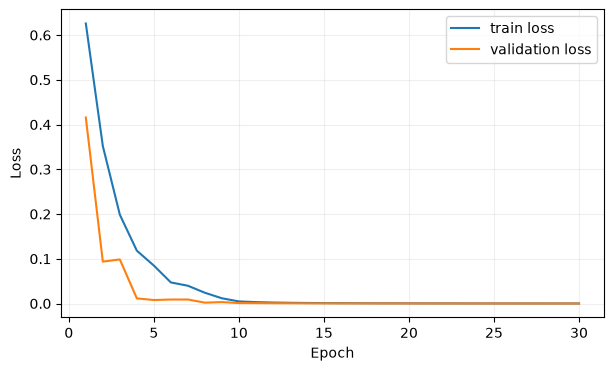

In [14]:
# Plot learning curves.
epochs = [x['epoch'] + 1 for x in history]
plt.figure(figsize=(7, 4))
plt.plot(epochs, [x['train_loss'] for x in history], label='train loss')
plt.plot(epochs, [x['val_loss'] for x in history], label='validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(alpha=0.2)
plt.show()


# Step 7 - Final held-out test evaluation

Only now, after the best checkpoint has been chosen from validation performance, load it and evaluate once on the test set.


In [15]:
model.load_state_dict(best_model_state)
test_metrics = evaluate(model, criterion, test_loader, device, conf)

print('Best validation epoch:', best_epoch + 1)
print('Final test metrics:')
for key, value in test_metrics.items():
    print(f'  {key}: {value:.4f}')



Best validation epoch: 2
Final test metrics:
  auc: 0.9395
  acc: 86.8217
  f1: 0.8617
  loss: 0.3064


# Step 8 -  Inspect Attention on One Slide

Attention is useful for understanding which instances contribute strongly to the learned bag representation, but attention weights should not automatically be interpreted as causal explanations.


Slide: test_001
Predicted class: 1
Attention shape: (1, 1, 17294)
Attention sum for first slide: 0.9999998807907104
Selected patches: 3458 / 17294
First selected indices: [0, 1, 2, 29, 53, 54, 78, 107, 143, 144, 145, 146, 149, 150, 188, 189, 190, 208, 209, 210]


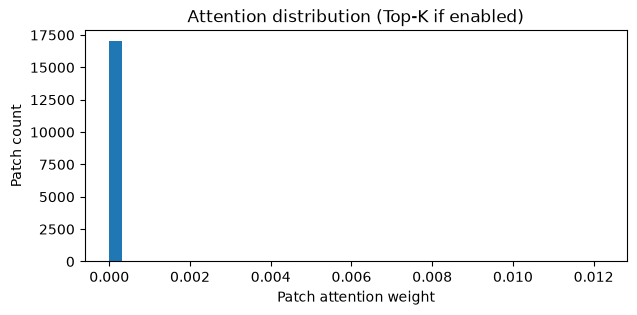

In [16]:
one_batch = mil_collate_fn([test_data[0]])
model.eval()
with torch.no_grad():
    logits, attention = model(
        one_batch['input'].to(device, dtype=torch.float32),
        return_attention=True,
    )

print('Slide:', one_batch['slide_id'][0])
print('Predicted class:', int(logits.argmax(dim=1)[0]))
print('Attention shape:', tuple(attention.shape))
print('Attention sum for first slide:', float(attention[0].sum()))

# Nonzero attention identifies selected patches in Top-K mode.
weights = attention[0, 0].detach().cpu()
selected_indices = torch.nonzero(weights > 0, as_tuple=True)[0]
print('Selected patches:', len(selected_indices), '/', len(weights))
print('First selected indices:', selected_indices[:20].tolist())
plt.figure(figsize=(7, 3))
plt.hist(weights.numpy(), bins=40)
plt.xlabel('Patch attention weight')
plt.ylabel('Patch count')
plt.title('Attention distribution (Top-K if enabled)')
plt.show()


## Visualize Attention on Whole-Slide Images (WSIs)

Before running the attention visualization, please complete the following steps:

1. Visit the [ECE1512-WSI-Feature dataset on Hugging Face](https://huggingface.co/datasets/LeonYe/ECE1512-WSI-Feature)

2. Download the original WSIs `test_067.tif` and `test_068.tif` and the corresponding tumor annotation file `test_068.xml`.

3. Create a folder named `slide/` under your project directory and place the downloaded files in this folder.

Run this cell after training and final test evaluation, with `DATASET = 'C16'`. It restores `best_model_state` and plots the two slides in `PROJECT_DIR/slide`:

- **test_068 (tumor):** attention overlay and green contours from `test_068.xml`, including a zoom of the annotated region.
- **test_067 (normal):** attention overlay without annotation contours, including a zoom around the highest-attention patch.

The blue rectangle marks the zoom shown on the right. Colors show **attention percentiles within each slide**, not patch tumor probabilities; areas without extracted patches stay transparent. The displayed `P(tumor)` is the model's slide-level prediction.

HDF5 patch coordinates and XML contour coordinates are assumed to be expressed in level-0 `(x, y)`  coordinates; patch coordinates are treated as top-left corners. The function parameter `patch_size_level0=512` is an editable **assumption** for the patch footprint because these HDF5 files do not store patch-size metadata. Match it to the feature extractor's patch size for an exact footprint. All visualization functions are in `wsi_visualization.py`; the cell below only calls `visualize_wsi_attention`.

[OpenSlide Python](https://openslide.org/api/python/) reads a thumbnail and a pyramid-level crop rather than loading the full-resolution WSI into memory. If dependencies are missing, run `%pip install openslide-python openslide-bin` and restart the kernel if needed. Raw per-patch attention and coordinates are retained in `attention_visualizations`.


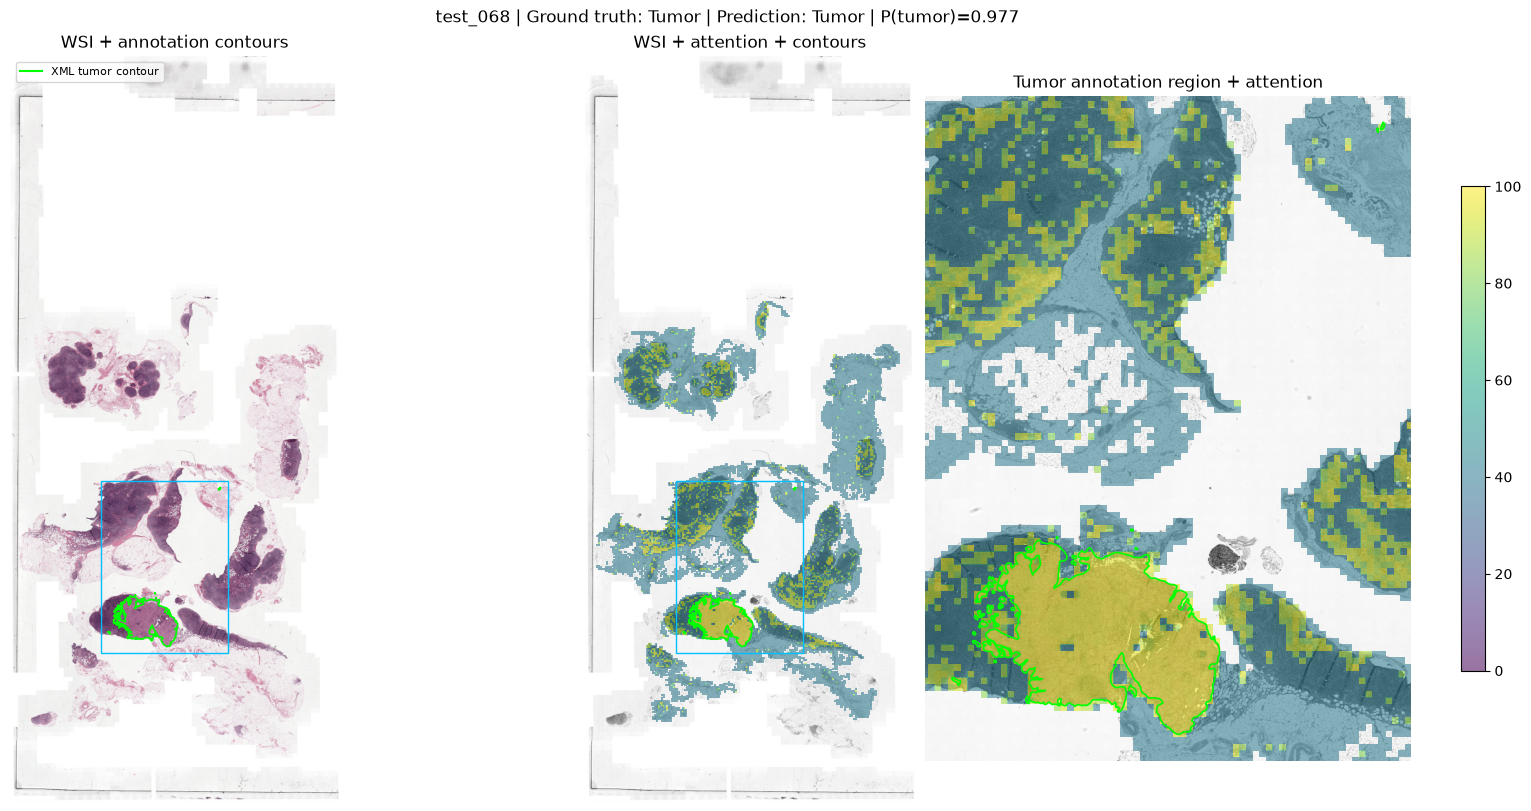

test_068: 15,037 patches; attention sum=1.000000; 45 annotation contours


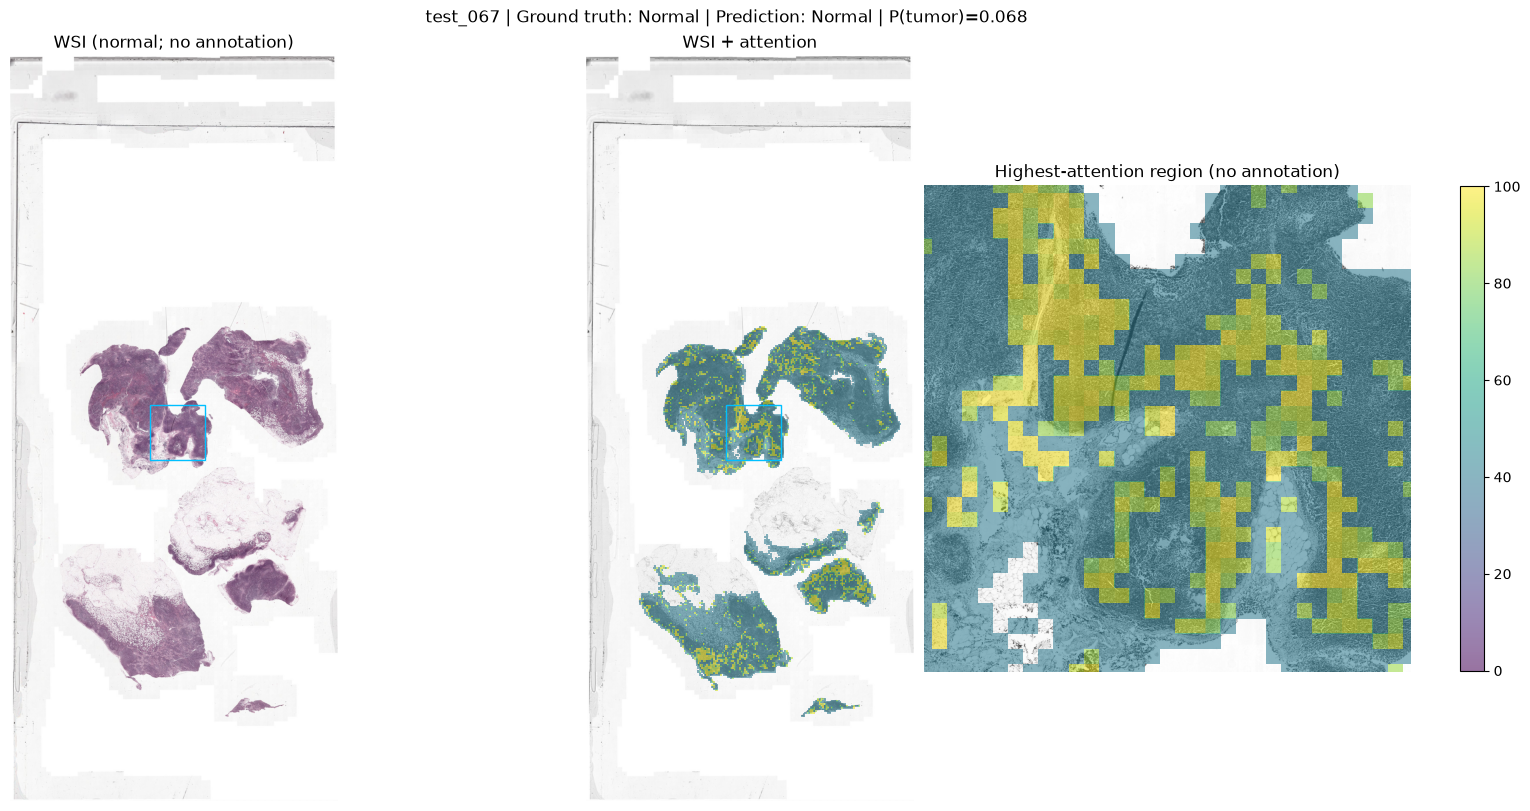

test_067: 11,926 patches; attention sum=1.000000; 0 annotation contours (no XML available)


In [17]:
# Only C16 has the slide/image examples described above.
# The helper implementation is external; verify it supports zero attention weights.
if DATASET == 'C16':
    attention_visualizations = visualize_wsi_attention(model, conf, PROJECT_DIR, best_model_state)
else:
    print('WSI visualization example is configured for C16 only.')
